In [2]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")                      # về thư mục gốc project
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.basics import split_genres, convert_timestamp, weighted_rating, filter_movies_by_count, split_title_year

In [3]:
assert split_genres("Action|Drama") == ["Action", "Drama"]
assert split_genres("(no genres listed)") == []
assert convert_timestamp(0) == "1970-01-01"
assert round(weighted_rating(300, 4.4, 50, 3.5), 2) == 4.27

In [4]:
import csv

movies = []                                   # list
with open("data/raw/ml-latest-small/movies.csv", encoding="utf-8") as f:
    for row in csv.DictReader(f):             # mỗi row là 1 dict
        movies.append({
            "movieId": int(row["movieId"]),
            "title": row["title"],
            "genres": split_genres(row["genres"]),   # list trong dict
        })
print(len(movies), movies[0])
movie_lookup = {m["movieId"]: m for m in movies}   # dict comprehension

stats = {}   # movieId -> {'sum':..., 'count':...}
with open("data/raw/ml-latest-small/ratings.csv", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        mid = int(row["movieId"])
        r = float(row["rating"])
        if mid not in stats:
            stats[mid] = {"sum": 0.0, "count": 0}
        stats[mid]["sum"] += r
        stats[mid]["count"] += 1

movie_stats = [
    {"title": movie_lookup[mid]["title"], "count": s["count"], "mean": s["sum"] / s["count"]}
    for mid, s in stats.items()
]
all_genres = set()
for m in movies:
    all_genres.update(m["genres"])          # thêm nhiều phần tử, tự bỏ trùng
print(len(all_genres), sorted(all_genres))

# phép giao: genre chung của 2 phim
toy_story = set(movie_lookup[1]["genres"])
jumanji   = set(movie_lookup[2]["genres"])
print(toy_story & jumanji)                  # intersection
print(toy_story | jumanji)                  # union
THRESHOLDS = (50, 3.5)                      # không ai sửa nhầm được
top = filter_movies_by_count(movie_stats, THRESHOLDS)

9742 {'movieId': 1, 'title': 'Toy Story (1995)', 'genres': ['Adventure', 'Animation', 'Children', 'Comedy', 'Fantasy']}
19 ['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
{'Adventure', 'Fantasy', 'Children'}
{'Adventure', 'Comedy', 'Fantasy', 'Children', 'Animation'}


In [5]:
import io, zipfile, requests
from pathlib import Path

URL = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
RAW = Path("data/raw")

def download_movielens(url=URL, dest=RAW):
    if (dest / "ml-latest-small" / "ratings.csv").exists():
        print("Đã có dữ liệu, bỏ qua tải.")
        return
    resp = requests.get(url, timeout=60)
    resp.raise_for_status()                    # lỗi HTTP -> raise exception
    with zipfile.ZipFile(io.BytesIO(resp.content)) as z:
        z.extractall(dest)
    print("Đã tải và giải nén vào", dest)
import re
import pandas as pd
from bs4 import BeautifulSoup

WIKI = "https://en.wikipedia.org/wiki/List_of_highest-grossing_films"
HEADERS = {"User-Agent": "PSD301M-StudentProject/1.0 (contact: your_email@fpt.edu.vn)"}

def scrape_grossing_films():
    html = requests.get(WIKI, headers=HEADERS, timeout=30).text
    soup = BeautifulSoup(html, "lxml")
    table = soup.find("table", class_="wikitable")         # bảng đầu tiên
    rows = []
    for tr in table.find_all("tr")[1:]:                     # bỏ hàng tiêu đề
        cells = [c.get_text(" ", strip=True) for c in tr.find_all(["th", "td"])]
        if len(cells) < 5:
            continue
        rank, peak, title, gross, year = cells[:5]
        title = re.sub(r"\[.*?\]", "", title).strip()       # bỏ chú thích [1], [# 2]
        gross = int(re.sub(r"[^0-9]", "", gross.split("$")[-1]) or 0)
        rows.append({"rank": rank, "title": title, "worldwide_gross": gross,
                     "year": int(re.findall(r"\d{4}", year)[0])})
    return pd.DataFrame(rows)
def normalize_title(title):
    title = re.sub(r"\s*\(\d{4}\)\s*$", "", title)            # bỏ (2008)
    m = re.match(r"^(.*), (The|A|An)$", title)
    if m:
        title = f"{m.group(2)} {m.group(1)}"                  # đưa The lên đầu
    return re.sub(r"[^a-z0-9 ]", "", title.lower()).strip()


In [7]:
import numpy as np
import pandas as pd

ratings = pd.read_csv("data/raw/ml-latest-small/ratings.csv")
movie_stats = ratings.groupby("movieId")["rating"].agg(count="size", mean="mean").reset_index()

r = ratings["rating"].to_numpy()             # Series -> ndarray
print(r.dtype, r.shape)
# 1. Thống kê mô tả
print("mean", np.mean(r), "median", np.median(r), "std", np.std(r))
print("min/max", r.min(), r.max())
print("P25, P75", np.percentile(r, [25, 75]))

# 2. Boolean mask: tỉ lệ rating >= 4
print("Tỉ lệ rating cao:", np.mean(r >= 4))   # mean của True/False = tỉ lệ

# 3. Đếm tần suất từng mức sao
levels, counts = np.unique(r, return_counts=True)
for lv, c in zip(levels, counts):
    print(lv, c)

# 4. Weighted rating vectorized cho mọi phim cùng lúc
v = movie_stats["count"].to_numpy()
R = movie_stats["mean"].to_numpy()
C = r.mean()
m = np.percentile(v, 90)                       # ngưỡng: top 10% số lượt
wr = (v / (v + m)) * R + (m / (v + m)) * C

# 5. Chuẩn hóa z-score và tương quan
z = (R - R.mean()) / R.std()
print("corr(count, mean):", np.corrcoef(v, R)[0, 1])
print("corr(log count, mean):", np.corrcoef(np.log1p(v), R)[0, 1])

float64 (100836,)
mean 3.501556983616962 median 3.5 std 1.0425240696180562
min/max 0.5 5.0
P25, P75 [3. 4.]
Tỉ lệ rating cao: 0.4817723828791305
0.5 1370
1.0 2811
1.5 1791
2.0 7551
2.5 5550
3.0 20047
3.5 13136
4.0 26818
4.5 8551
5.0 13211
corr(count, mean): 0.1272585735956063
corr(log count, mean): 0.11191732616730098


In [8]:
import pandas as pd
base = "data/raw/ml-latest-small/"
movies  = pd.read_csv(base + "movies.csv")
ratings = pd.read_csv(base + "ratings.csv")
tags    = pd.read_csv(base + "tags.csv")
for name, df in [("movies", movies), ("ratings", ratings), ("tags", tags)]:
    print(name, df.shape)
    print(df.isna().sum(), df.duplicated().sum())
ratings.describe()
movies["year"] = movies["title"].str.extract(r"\((\d{4})\)\s*$").astype("float")
movies["clean_title"] = movies["title"].str.replace(r"\s*\(\d{4}\)\s*$", "", regex=True)
movies["genre_list"] = movies["genres"].apply(split_genres)     # tái dùng hàm Phase 1
ratings["datetime"] = pd.to_datetime(ratings["timestamp"], unit="s")
ratings["rating_year"] = ratings["datetime"].dt.year
movie_genres = movies[["movieId", "genre_list"]].explode("genre_list") \
                     .rename(columns={"genre_list": "genre"}).dropna(subset=["genre"])
rated = ratings.merge(movies[["movieId", "clean_title", "year", "genres"]], on="movieId", how="left")
rated_genre = ratings.merge(movie_genres, on="movieId", how="inner")
print(len(ratings), len(rated), len(rated_genre))   # kiểm tra số dòng sau merge
# Q1: genre summary
genre_summary = (rated_genre.groupby("genre")
                 .agg(avg_rating=("rating", "mean"), median_rating=("rating", "median"),
                      n_ratings=("rating", "size"), n_movies=("movieId", "nunique"))
                 .query("n_ratings >= 500")
                 .sort_values("avg_rating", ascending=False).round(3))

# Q2: theo năm đánh giá
yearly = rated.groupby("rating_year")["rating"].agg(["mean", "count"])

# Q3: phân bố
ratings["rating"].value_counts().sort_index()

# Q4 + Q5: thống kê theo phim, weighted rating
movie_stats = rated.groupby(["movieId", "clean_title", "year"]) \
                   .agg(n_ratings=("rating", "size"), avg_rating=("rating", "mean")).reset_index()
C = ratings["rating"].mean()
m = movie_stats["n_ratings"].quantile(0.90)
v, R = movie_stats["n_ratings"], movie_stats["avg_rating"]
movie_stats["weighted_rating"] = (v / (v + m)) * R + (m / (v + m)) * C
top_movies = movie_stats[movie_stats["n_ratings"] >= m] \
                .sort_values("weighted_rating", ascending=False).head(20)

print(movie_stats[["n_ratings", "avg_rating"]].corr())


movies (9742, 3)
movieId    0
title      0
genres     0
dtype: int64 0
ratings (100836, 4)
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64 0
tags (3683, 4)
userId       0
movieId      0
tag          0
timestamp    0
dtype: int64 0
100836 100836 274433
            n_ratings  avg_rating
n_ratings    1.000000    0.127762
avg_rating   0.127762    1.000000


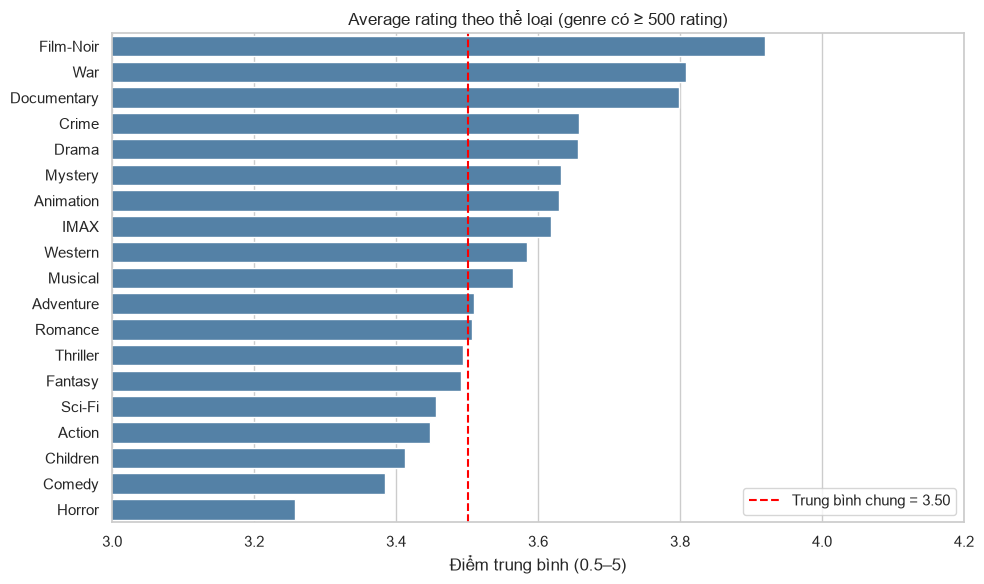

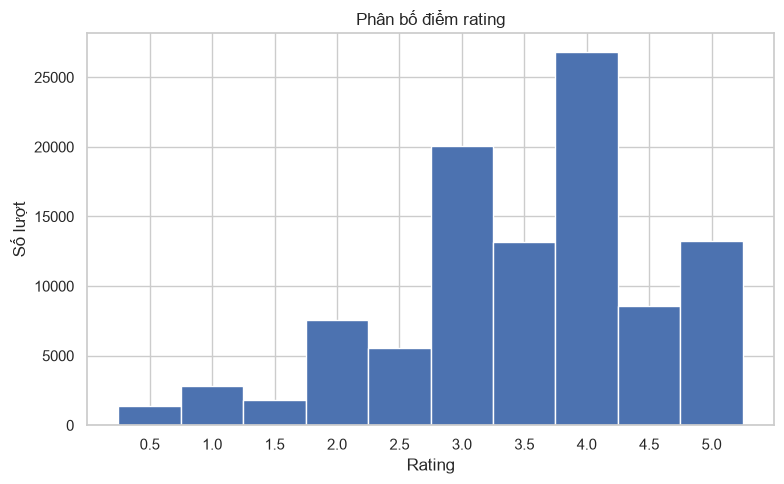

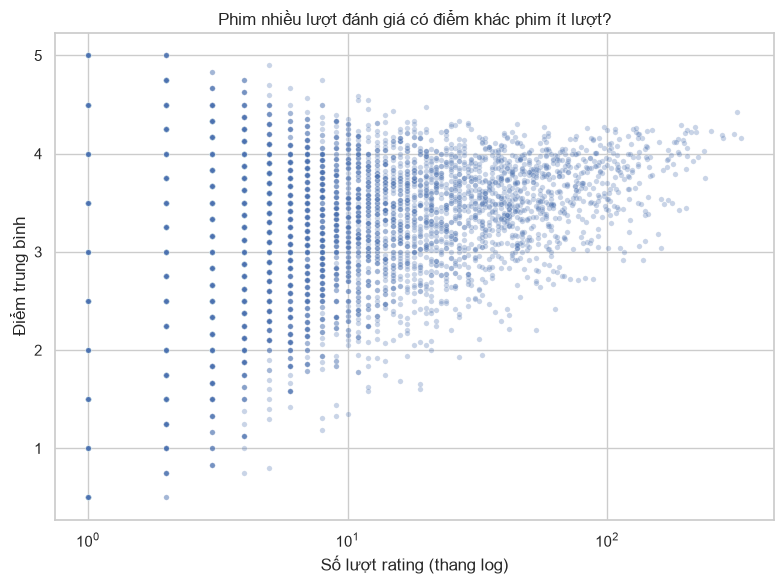

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

# 1. Bar: genre
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=genre_summary.reset_index(), y="genre", x="avg_rating", ax=ax, color="steelblue")
ax.axvline(C, ls="--", color="red", label=f"Trung bình chung = {C:.2f}")
ax.set(title="Average rating theo thể loại (genre có ≥ 500 rating)", xlabel="Điểm trung bình (0.5–5)", ylabel="")
ax.set_xlim(3, 4.2); ax.legend()
fig.tight_layout(); fig.savefig("figures/01_genre_bar.png", dpi=150)

# 2. Histogram: rating
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(ratings["rating"], bins=np.arange(0.25, 5.5, 0.5), edgecolor="white")
ax.set(title="Phân bố điểm rating", xlabel="Rating", ylabel="Số lượt")
ax.set_xticks(np.arange(0.5, 5.5, 0.5))
fig.tight_layout(); fig.savefig("figures/02_rating_hist.png", dpi=150)

# 3. Scatter: số lượt vs điểm
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=movie_stats, x="n_ratings", y="avg_rating", alpha=0.3, s=15, ax=ax)
ax.set_xscale("log")
ax.set(title="Phim nhiều lượt đánh giá có điểm khác phim ít lượt?",
       xlabel="Số lượt rating (thang log)", ylabel="Điểm trung bình")
fig.tight_layout(); fig.savefig("figures/03_count_vs_rating.png", dpi=150)

In [10]:
import sys; sys.path.append("..")
from src.data_processor import MovieDataProcessor
p = MovieDataProcessor(min_genre_ratings=500).run()
p.genre_summary.head()

[load] Dữ liệu đã có, bỏ qua tải.
[load] movies=(9742, 3), ratings=(100836, 4), tags=(3683, 4)
[clean] ratings=100836, rated=100836, rated_genre=274433
[genre] 19 genre đạt ngưỡng; cao nhất: Film-Noir
[movies] C=3.502, m=27, corr(log count, avg)=0.112
[export] Đã lưu vào data\processed


,genre,avg_rating,median_rating,std_rating,n_ratings,n_movies
0,Film-Noir,3.920,4.0,0.887,870,85
1,War,3.808,4.0,0.979,4859,381
2,Documentary,3.798,4.0,0.820,1219,438
3,Crime,3.658,4.0,0.995,16681,1196
4,Drama,3.656,4.0,0.979,41928,4349
